# Una batería sobre tu propia muestra puntuada: contrato 1, run_suite y los semáforos

**Pregunta:** Si traes una muestra puntuada propia, ¿una batería de pruebas del motor, ejecutada bajo una política, encuentra la muestra cuyas PD son demasiado bajas y deja en paz a la calibrada, y qué pruebas sostienen el hallazgo?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** notebooks 01 a 03 de este tema
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este notebook puedes:

- pasar un CSV de deudores puntuados por el contrato 1 y leer qué acepta, qué señala y qué rechaza, y por qué nunca fuerza un valor;
- asignar PD a la escala maestra y construir la tabla de grados que leen las pruebas por grado;
- armar una batería de pruebas del motor y ejecutarla bajo una política con `run_suite`, que no se detiene en el primer fallo;
- abrir tres de las pruebas (el PSI, Hosmer-Lemeshow y el chi-cuadrado sobre grados) y decir cuáles son los grados de libertad y la referencia de cada una;
- explicar por qué las pruebas de nivel y la de estabilidad son rojas en la muestra actual mientras la de ordenamiento sigue verde.

## Preparación

Instala el entorno fijado una vez, en un entorno virtual, con el comando habitual:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2 pandas==3.0.6
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti.

Este notebook importa además dos lectores del proceso de datos del producto: el contrato 1 (`pipeline.io.contract`) y la escala maestra (`pipeline.core.calibration`). El proceso de datos son scripts sueltos y no un paquete, así que el notebook pone `data-pipeline/` en la ruta de importación y los importa desde allí: un solo lector para el proceso, las pruebas y estos notebooks, nunca una copia. La celda siguiente lo hace e imprime las versiones.

In [1]:
# Pone el proceso de datos en la ruta de importación, importa los lectores y el motor, e imprime las versiones
import importlib.metadata as md
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from riskvalidation.core.policy import default_policy
from riskvalidation.core.suite import run_suite
from riskvalidation.validation import calibration as cal
from riskvalidation.validation import discrimination as disc
from riskvalidation.validation import stability as st

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.core.calibration import GRADES, MASTER_SCALE_UPPER, grade_table
from pipeline.io import contract
from pipeline.io.formats import read_csv_rows

for name in ("riskvalidation", "numpy", "matplotlib", "pandas"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2
pandas 3.0.6


## Datos

Las mismas dos muestras sintéticas con verdad conocida del notebook 03, confirmadas en `data/examples/` (propietario: este repositorio; sin licencia de terceros, MIT; generadas a partir de una semilla por `data-pipeline/pipeline/io/examples.py`):

- `scored_sample_development.csv`: 2.000 deudores al 2024-12-31, PD calibradas por construcción. Hace de **muestra de desarrollo**, la referencia con la que se compara un validador.
- `scored_sample_current.csv`: 2.000 deudores al 2025-12-31 de una población más riesgosa cuyos incumplimientos llegan a 1,5 veces la PD. Es la **muestra bajo validación**.

Tu propio modelo entra del mismo modo: un CSV con `id`, `observation_date`, `target` y `pd`, una fila por deudor. La forma es la familia `scored_sample` del contrato 1 (`docs/guides/02_validate-your-own-model.md`). Ambos archivos se leen más abajo, a través del contrato 1, en el paso 2.

## Método

La ruta de un modelo que traes a Contraste tiene cinco estaciones: el contrato que decide qué filas pueden entrar, la escala maestra que agrupa deudores en grados, la batería de pruebas que lee la muestra, la política que colorea los resultados y la tabla de semáforos que lee un validador. La recorremos con las dos muestras y abrimos tres pruebas en el camino para ver de qué están hechos sus semáforos.

### Paso 1: el contrato 1 lee, señala y rechaza, y nunca fuerza

El contrato 1 interpreta cada valor según su tipo declarado. Una PD de 1,2, un desenlace `yes` o una segunda fila con el mismo identificador en la misma fecha se **rechaza**, con el campo, el valor y lo que se esperaba; un valor raro pero utilizable se **señala**; una columna que la familia no declara se enumera como **ignorada** y no se usa jamás. Nada se repara en silencio, porque un valor reparado es un número que el validador no vio. La celda siguiente muestra la regla en cinco filas escritas a mano, tres de ellas erróneas.

In [2]:
# Cinco filas a mano: dos válidas y tres que el contrato 1 debe rechazar (PD de 1,2, desenlace "yes", id repetido)
KIND = {"rejected": "rechazada", "flagged": "señalada"}
planted = [
    {"id": "A1", "observation_date": "2025-12-31", "target": "0", "pd": "0.05", "segment": "retail"},
    {"id": "A2", "observation_date": "2025-12-31", "target": "1", "pd": "1.2", "segment": "retail"},
    {"id": "A3", "observation_date": "2025-12-31", "target": "yes", "pd": "0.30", "segment": "retail"},
    {"id": "A1", "observation_date": "2025-12-31", "target": "1", "pd": "0.10", "segment": "retail"},
    {"id": "A5", "observation_date": "2025-12-31", "target": "1", "pd": "0.20", "segment": "retail", "extra": "x"},
]
report = contract.validate("scored_sample", planted)
counts = report.counts()
print("contrato 1 sobre las cinco filas:", counts["input"], "leídas,", counts["accepted"], "aceptadas")
print(counts["rejected"], "rechazadas,", counts["flagged"], "señaladas")
print("columnas ignoradas:", report.ignored_columns)
shown = [
    {"veredicto": KIND[e["kind"]], "fila": e["row"], "campo": e["field"], "valor": e["value"]}
    for e in report.examples()
]
pd.DataFrame(shown)

contrato 1 sobre las cinco filas: 5 leídas, 2 aceptadas
3 rechazadas, 0 señaladas
columnas ignoradas: ['extra']


,veredicto,fila,campo,valor
0,rechazada,1,pd,1.2
1,rechazada,2,target,yes
2,rechazada,3,id,A1


El contrato 1 rechazó exactamente los tres errores plantados, cada uno con su fila, campo y valor: la PD de 1,2 (fuera de rango para una probabilidad), el desenlace `yes` (no es 0 ni 1) y el identificador repetido `A1` en la misma fecha. Aceptó las otras dos filas y enumeró `extra` como columna ignorada. La tabla dice qué está mal y dónde, y la regla de cada veredicto está en el texto del propio contrato. No muestra qué hace el contrato con un valor solo raro; eso es el conteo de `señaladas`, cero aquí.

### Paso 2: los dos archivos reales

`read_csv_rows` lee el texto sin interpretarlo, `contract.validate` aplica la familia y los arreglos que necesita la batería salen solo de los registros **aceptados**. La celda siguiente lo hace con ambos archivos e imprime lo que decidió el contrato 1.

In [3]:
# Lee ambos archivos con el contrato 1 y conserva los registros aceptados como arreglos: PD primero, desenlaces después
samples = {}
rows_table = []
for name in ("development", "current"):
    rows = read_csv_rows(ROOT / "data" / "examples" / f"scored_sample_{name}.csv")
    checked = contract.validate("scored_sample", rows)
    counts = checked.counts()
    pd_values = np.array([r["pd"] for r in checked.accepted])
    samples[name] = (pd_values, np.array([r["target"] for r in checked.accepted]))
    rows_table.append(
        {
            "archivo": f"scored_sample_{name}.csv",
            "leídas": counts["input"],
            "aceptadas": counts["accepted"],
            "rechazadas": counts["rejected"],
            "señaladas": counts["flagged"],
        }
    )
pd_dev, y_dev = samples["development"]
pd_cur, y_cur = samples["current"]
pd.DataFrame(rows_table)

,archivo,leídas,aceptadas,rechazadas,señaladas
0,scored_sample_development.csv,2000,2000,0,0
1,scored_sample_current.csv,2000,2000,0,0


Ambos archivos pasan completos: 2.000 filas leídas y 2.000 aceptadas cada uno, sin nada rechazado ni señalado, de modo que los arreglos siguientes contienen a todos los deudores. Un archivo con errores habría vuelto con menos filas aceptadas y con las razones, y el validador tendría que decidir qué hacer antes de que corriera cualquier prueba. El notebook nunca descarta una fila por su cuenta.

### Paso 3: la escala maestra y la tabla de grados

Las pruebas de tipo calificación no leen una PD por deudor. Leen **grados**, grupos de deudores de riesgo parecido, cada uno con su conteo, sus incumplimientos y su PD media. Contraste asigna las PD a una escala maestra geométrica: cotas superiores de 1 % por 1,5 elevado a k para k = 0 a 10, y luego 100 %, doce grados en total. La celda siguiente imprime la escala y construye la tabla de grados de la muestra actual, sin los grados vacíos.

In [4]:
# Asigna la muestra actual a la escala maestra e imprime los grados no vacíos
print("grados de la escala maestra:", len(GRADES))
print("primeras cotas superiores:", [round(b, 4) for b in MASTER_SCALE_UPPER[:4]])
table = [g for g in grade_table(pd_cur, y_cur) if g["n"] > 0]
grades = pd.DataFrame(table)[["grade", "hi", "n", "d", "pd", "dr"]].round(4)
names = ["grado", "cota superior", "deudores", "incumplimientos", "PD media", "tasa"]
grades.columns = names
grades

grados de la escala maestra: 12
primeras cotas superiores: [0.01, 0.015, 0.0225, 0.0338]


,grado,cota superior,deudores,incumplimientos,PD media,tasa
0,G01,0.0100,189,1,0.0052,0.0053
1,G02,0.0150,115,1,0.0125,0.0087
2,G03,0.0225,155,3,0.0188,0.0194
3,G04,0.0338,207,6,0.0278,0.0290
4,G05,0.0506,290,22,0.0419,0.0759
5,G06,0.0759,352,25,0.0626,0.0710
6,G07,0.1139,317,48,0.0926,0.1514
7,G08,0.1709,233,49,0.1388,0.2103
8,G09,0.2563,121,43,0.2039,0.3554
9,G10,0.3844,20,9,0.3002,0.4500


Existen doce grados y once están ocupados: G12 está vacío y G11 contiene un solo deudor. Mira la columna de tasa frente a la PD media: en los primeros cuatro grados la tasa observada sigue a la PD (0,0053 frente a 0,0052 en G01, 0,0290 frente a 0,0278 en G04), y desde G05 se adelanta (0,0759 frente a 0,0419 en G05, 0,3554 frente a 0,2039 en G09). La tabla es la materia prima de las pruebas por grado y ya insinúa el hallazgo, pero una tabla de tasas no puede decir si la brecha es más que el azar; las pruebas sí.

### Paso 4: las tareas de una batería

Una batería es una lista de tareas, cada una un par de una prueba del motor y sus argumentos, y `run_suite` las ejecuta en orden bajo una política. Las tareas de una validación de PD son estas:

| Prueba | Qué pregunta | Referencia |
|---|---|---|
| `disc.auc` | ¿la PD ordena a los que incumplen por encima de los que no? | ECB 2019, Anexo 1 (sección 3.1) |
| `disc.auc_vs_initial` | ¿el ordenamiento se ha deteriorado desde el desarrollo (unilateral)? | ECB 2019, sección 2.5.4.1 |
| `pd.jeffreys`, `pd.binomial` | ¿la PD de la cartera es demasiado baja? | ECB 2019; BCBS WP14 |
| `pd.binomial_vasicek` | lo mismo, admitiendo una correlación de incumplimiento de un factor (rho = 0,04, el valor de Basilea para minorista renovable) | BCBS WP14 |
| `pd.chi2_grades` | ¿los incumplimientos de todos los grados coinciden con sus PD? | BCBS WP14 |
| `pd.hosmer_lemeshow`, `pd.spiegelhalter` | ¿las PD a nivel de deudor coinciden con los desenlaces? | Hosmer y Lemeshow 1980; Spiegelhalter 1986 |
| `stability.psi` | ¿se ha movido la distribución de las PD desde el desarrollo? | Yurdakul y Naranjo 2020 |

Siete tareas necesitan solo la muestra. La celda siguiente las enumera para cada muestra, con las entradas que lee cada una: los totales de la cartera, los grados o los arreglos a nivel de deudor.

In [5]:
# Una batería por muestra: una lista de pares (prueba del motor, argumentos); el motor calcula al ejecutar
RHO = 0.04
NAMES = {"development": "desarrollo", "current": "actual"}
batteries = {}
for name, (pd_s, y_s) in samples.items():
    grades_s = [g for g in grade_table(pd_s, y_s) if g["n"] > 0]
    level = dict(n=len(y_s), d=int(y_s.sum()), pd=float(pd_s.mean()))
    grade_args = dict(n=[g["n"] for g in grades_s], d=[g["d"] for g in grades_s], pd=[g["pd"] for g in grades_s])
    batteries[name] = [
        (disc.disc_auc, dict(risk=pd_s, defaults=y_s)),
        (cal.pd_jeffreys, level),
        (cal.pd_binomial, level),
        (cal.pd_binomial_vasicek, dict(**level, rho=RHO)),
        (cal.pd_chi2_grades, grade_args),
        (cal.pd_hosmer_lemeshow, dict(defaults=y_s, pd=pd_s, fitted=False)),
        (cal.pd_spiegelhalter, dict(defaults=y_s, pd=pd_s)),
    ]
print("tareas de la batería:", [func.__name__ for func, _ in batteries["development"]])

tareas de la batería: ['disc_auc', 'pd_jeffreys', 'pd_binomial', 'pd_binomial_vasicek', 'pd_chi2_grades', 'pd_hosmer_lemeshow', 'pd_spiegelhalter']


Las siete tareas quedan armadas para ambas muestras, y el motor todavía no ha calculado nada: una tarea es solo una función y sus argumentos. Dos pruebas comparan la muestra con el desarrollo y necesitan una referencia: el AUC frente al inicial, que lleva la varianza propia del AUC de desarrollo porque ignorarla hace que la prueba rechace más a menudo que su nivel cuando nada ha cambiado, y el PSI, cuyos diez intervalos son los deciles de las PD de desarrollo, fijados antes de ver la muestra actual. La celda siguiente calcula esas dos entradas con el motor y suma las dos tareas solo a la batería actual, porque la muestra de desarrollo se compararía consigo misma.

In [6]:
# Con la muestra de desarrollo como referencia, dos tareas se suman a la batería actual: el AUC frente a ella y el PSI
auc_ref, variance_ref, *_ = disc.auc_with_variance(pd_dev, y_dev)
edges = st.quantile_edges(pd_dev, 10)
reference_tasks = [
    (disc.disc_auc_vs_initial, dict(auc_initial=float(auc_ref), risk=pd_cur, defaults=y_cur,
                                    auc_initial_variance=float(variance_ref))),
    (st.stability_psi, dict(expected_counts=st.bin_counts(pd_dev, edges), actual_counts=st.bin_counts(pd_cur, edges))),
]
batteries["current"] = batteries["current"] + reference_tasks
print("tareas de la batería actual con la referencia:", [func.__name__ for func, _ in batteries["current"]])

tareas de la batería actual con la referencia: ['disc_auc', 'pd_jeffreys', 'pd_binomial', 'pd_binomial_vasicek', 'pd_chi2_grades', 'pd_hosmer_lemeshow', 'pd_spiegelhalter', 'disc_auc_vs_initial', 'stability_psi']


La batería actual tiene nueve tareas y la de desarrollo siete. Dos decisiones en los argumentos merecen un comentario. `fitted=False` dice a Hosmer-Lemeshow que las PD se dieron antes de los desenlaces, así que usa tantos grados de libertad como grupos, mientras que un modelo ajustado sobre la muestra perdería dos. Y `rho = 0.04` en la binomial ajustada de Vasicek es la correlación de activos de las exposiciones minoristas renovables de Basilea, un supuesto escrito en la tarea y no uno que respalden los datos.

### Paso 5: ejecutar las baterías

`run_suite` recibe las tareas, la política y los identificadores, ejecuta cada tarea y devuelve un `SuiteRun` con un `TestResult` por tarea. La celda siguiente ejecuta ambas baterías bajo la política por defecto, imprime los conteos de semáforos y el peor semáforo de cada una, y el AUC de cada muestra.

In [7]:
# Ejecuta cada batería con la política por defecto; run_suite da a cada resultado el mismo modelo y segmento
LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "sin evaluar", "error": "error"}
policy = default_policy()
suites = {
    name: run_suite(tasks, policy=policy, model_id=name, segment="portfolio")
    for name, tasks in batteries.items()
}
by_test = {name: {r.test_id: r for r in suite.results} for name, suite in suites.items()}
print("política:", suites["current"].policy_version)
for name, suite in suites.items():
    shown = {LIGHT[key]: value for key, value in suite.counts().items() if value}
    print(f"{NAMES[name]}: conteos: {shown} | peor semáforo: {LIGHT[suite.worst().value]}")
    print(f"    AUC: {by_test[name]['disc.auc'].metric:.3f}")

política: riskvalidation-default 2026.10.1
desarrollo: conteos: {'verde': 6, 'sin evaluar': 1} | peor semáforo: verde
    AUC: 0.743
actual: conteos: {'verde': 2, 'rojo': 6, 'sin evaluar': 1} | peor semáforo: rojo
    AUC: 0.779


La muestra de desarrollo sale con seis resultados verdes y uno sin evaluar, y su peor semáforo es verde. La muestra actual tiene seis resultados rojos, dos verdes y uno sin evaluar, de modo que su peor semáforo es rojo. El único resultado sin color en cada una es el AUC, que la política por defecto deja sin color, como vio el notebook 02. El AUC mismo es 0,743 en la muestra de desarrollo y 0,779 en la actual: el ordenamiento no empeoró. Los conteos dicen que la batería separa las dos muestras; la tabla siguiente dice qué pruebas lo hacen.

### Paso 6: la tabla de semáforos

La celda siguiente alinea, para cada prueba, el valor p y el semáforo en ambas muestras. Un guion es una prueba que no se ejecutó en esa muestra o un resultado sin valor p.

In [8]:
# La tabla de semáforos: para cada prueba, el valor p y el semáforo en ambas muestras
lights = []
for test_id in by_test["current"]:
    row = {"prueba": test_id}
    for name in suites:
        result = by_test[name].get(test_id)
        p_text = "-" if result is None or result.p_value is None else f"{result.p_value:.3g}"
        row[f"valor p ({NAMES[name]})"] = p_text
        row[f"semáforo ({NAMES[name]})"] = "-" if result is None else LIGHT[result.light.value]
    lights.append(row)
pd.DataFrame(lights)

,prueba,valor p (desarrollo),semáforo (desarrollo),valor p (actual),semáforo (actual)
0,disc.auc,-,sin evaluar,-,sin evaluar
1,pd.jeffreys,0.863,verde,6.05e-09,rojo
2,pd.binomial,0.874,verde,7.59e-09,rojo
3,pd.binomial_vasicek,0.54,verde,0.114,verde
4,pd.chi2_grades,0.509,verde,2.65e-07,rojo
5,pd.hosmer_lemeshow,0.687,verde,3.87e-09,rojo
6,pd.spiegelhalter,0.831,verde,3.64e-09,rojo
7,disc.auc_vs_initial,-,-,0.914,verde
8,stability.psi,-,-,4.21e-10,rojo


En la muestra de desarrollo todo valor p está lejos de los puntos de corte, entre 0,509 y 0,874, y todo semáforo es verde. En la muestra actual la prueba de Jeffreys (6,05e-09), la binomial (7,59e-09), el chi-cuadrado sobre grados (2,65e-07), Hosmer-Lemeshow (3,87e-09), Spiegelhalter (3,64e-09) y el PSI (4,21e-10) son rojos. Dos pruebas siguen verdes: el AUC frente al inicial, con un valor p de 0,914, y la binomial ajustada de Vasicek, con 0,114. La primera es el ordenamiento, que está intacto. La segunda es el fallo instructivo, que se discute después de la figura. La celda siguiente dibuja la tabla como evidencia.

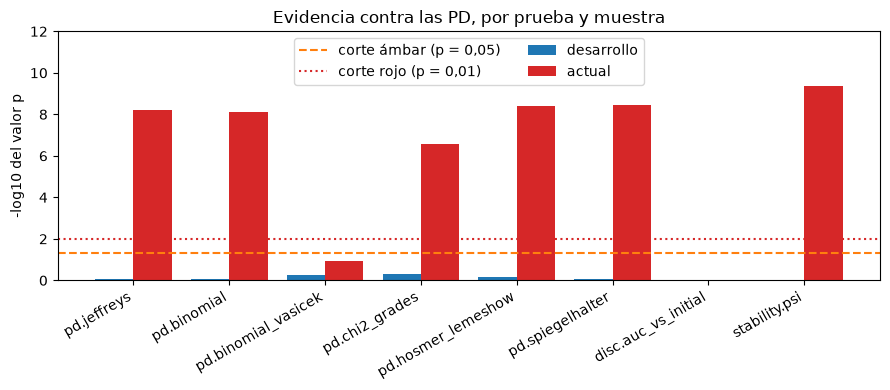

In [9]:
# Dibuja la evidencia de cada prueba contra las PD como -log10 de su valor p, para ambas muestras
tests = [t for t, r in by_test["current"].items() if r.p_value is not None]
positions = np.arange(len(tests))
fig, ax = plt.subplots(figsize=(9, 4))
for shift, name, colour in ((-0.2, "development", "tab:blue"), (0.2, "current", "tab:red")):
    p_values = [by_test[name][t].p_value if t in by_test[name] else 1.0 for t in tests]
    ax.bar(positions + shift, -np.log10(np.clip(p_values, 1e-300, 1)), width=0.4, color=colour, label=NAMES[name])
ax.axhline(-np.log10(0.05), color="tab:orange", linestyle="--", label="corte ámbar (p = 0,05)")
ax.axhline(2, color="tab:red", linestyle=":", label="corte rojo (p = 0,01)")
ax.set_xticks(positions)
ax.set_xticklabels(tests, rotation=30, ha="right")
ax.set_ylim(0, 12)
ax.set_ylabel("-log10 del valor p")
ax.set_title("Evidencia contra las PD, por prueba y muestra")
ax.legend(ncol=2, loc="upper center")
fig.tight_layout()
plt.show()

Cada barra es la fuerza de la evidencia contra las PD, menos el logaritmo en base 10 del valor p, de modo que una barra más alta es un valor p menor; las líneas discontinua y punteada son los cortes ámbar (p = 0,05) y rojo (p = 0,01). Las barras de desarrollo apenas se levantan del cero, y las barras actuales de las pruebas de nivel y ajuste llegan a entre 6,6 y 8,4 y la del PSI a cerca de 9,4, muy por encima del corte rojo. La barra de Vasicek es la única prueba de nivel bajo la línea roja, cerca de 1. La figura muestra evidencia, no tamaño: una barra alta dice con confianza que las PD son demasiado bajas, no en cuánto, y las dos pruebas con referencia no tienen barra de desarrollo porque comparan contra él.

El fallo de Vasicek merece una frase. Con una correlación de activos de 0,04 el exceso de incumplimientos de un periodo es compatible con un factor sistemático que movió toda la cartera, y un periodo no puede distinguir ambas cosas. Las pruebas que suponen incumplimientos independientes son las más sensibles; aquí la verdad son incumplimientos independientes a 1,5 veces la PD, así que el verde de Vasicek es un fallo, y el precio de admitir correlación es la potencia.

### Paso 7: el PSI, abierto

El PSI compara la proporción de cada muestra en $B$ intervalos fijados sobre la muestra de desarrollo. Con $E_i$ y $A_i$ los conteos de la muestra de desarrollo y de la actual en el intervalo $i$, $n = \sum_i E_i$, $m = \sum_i A_i$, $e_i = E_i / n$ y $a_i = A_i / m$:

$$\mathrm{PSI} = \sum_{i=1}^{B} (a_i - e_i)\,\ln\frac{a_i}{e_i}$$

Un intervalo vacío se acota en media observación para que el logaritmo siga siendo finito. La lectura habitual es una regla empírica, 0,10 y 0,25, usada sin referencia a tasas de error. Yurdakul y Naranjo (2020) muestran que, escalado por los dos tamaños de muestra, el PSI sigue una distribución chi-cuadrado con $B - 1$ grados de libertad cuando nada cambió:

$$\left(\frac{1}{n} + \frac{1}{m}\right)^{-1}\mathrm{PSI} \;\approx\; \chi^2_{B-1}$$

lo que da un valor p con la cola superior y el PSI crítico al nivel $\alpha$:

$$\mathrm{PSI}_{\mathrm{crit}} = \left(\frac{1}{n} + \frac{1}{m}\right)\chi^2_{1-\alpha,\,B-1}$$

El semáforo del motor sigue ese valor p. La celda siguiente lee el resultado del PSI de la batería actual y pide al motor el PSI crítico al 5 % con `psi_benchmark`.

In [10]:
# La fila del PSI de la batería actual, su escala y el PSI crítico que deriva el motor para estos tamaños de muestra
psi = by_test["current"]["stability.psi"]
n_dev, n_cur = psi.extras["n"], psi.extras["m"]
critical = st.psi_benchmark(n_dev, n_cur, bins=psi.extras["bins"], alpha=0.05)
scale = 1 / n_dev + 1 / n_cur
print("deudores por muestra:", n_dev, "/", n_cur, "| intervalos:", psi.extras["bins"])
print("escala 1/n + 1/m:", scale)
print("PSI:", round(psi.metric, 4), "| estadístico escalado:", round(psi.metric / scale, 3))
print("grados de libertad:", psi.extras["bins"] - 1, "| valor p:", format(psi.p_value, ".3g"))
print("PSI crítico al 5 %:", round(critical, 4))
print("contribución por intervalo:", [round(c, 4) for c in psi.extras["contributions"]])

deudores por muestra: 2000 / 2000 | intervalos: 10
escala 1/n + 1/m: 0.001
PSI: 0.0626 | estadístico escalado: 62.603
grados de libertad: 9 | valor p: 4.21e-10
PSI crítico al 5 %: 0.0169
contribución por intervalo: [0.0123, 0.0015, 0.0066, 0.0028, 0.0, 0.0, 0.0003, 0.0007, 0.0008, 0.0376]


El PSI de la muestra actual es 0,0626, que escalado por $(1/2000 + 1/2000)^{-1}$ es 62,603 con 9 grados de libertad: un valor p de 4,21e-10. El PSI crítico al 5 % para estos tamaños de muestra es 0,0169, de modo que 0,0626 es casi cuatro veces el valor que separa el azar del cambio. La lectura convencional lo llama poco cambio, porque está bajo 0,10; la referencia chi-cuadrado discrepa, y con 2.000 deudores por muestra es la que tiene una tasa de error conocida. La lista de contribuciones muestra dónde está el desplazamiento: el intervalo 10 solo aporta 0,0376 de los 0,0626, y los intervalos 1 y 3 suman 0,0123 y 0,0066. La celda siguiente dibuja la proporción de cada muestra por intervalo y las contribuciones.

deudores de desarrollo por intervalo: [200, 200, 200, 200, 200, 200, 200, 200, 200, 200]
deudores actuales por intervalo:       [136, 176, 152, 168, 200, 202, 190, 217, 218, 341]


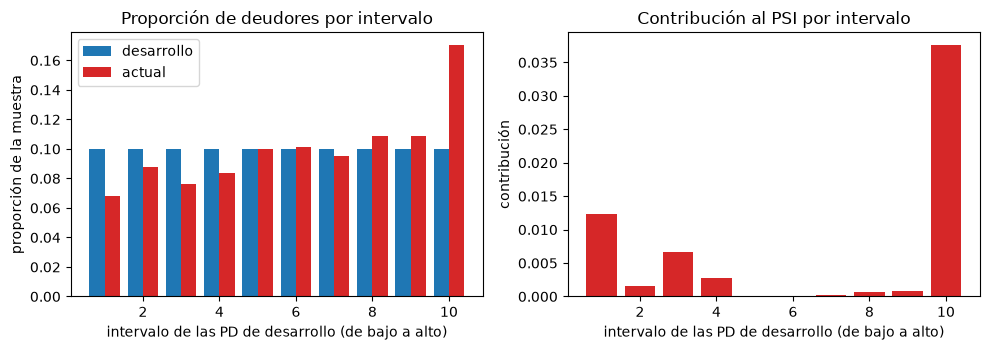

In [11]:
# Dibuja la proporción de cada muestra en los diez intervalos de las PD de desarrollo y su contribución al PSI
counts_dev = st.bin_counts(pd_dev, edges)
counts_cur = st.bin_counts(pd_cur, edges)
print("deudores de desarrollo por intervalo:", counts_dev.tolist())
print("deudores actuales por intervalo:      ", counts_cur.tolist())
share_dev = counts_dev / len(pd_dev)
share_cur = counts_cur / len(pd_cur)
bins = np.arange(1, len(share_dev) + 1)
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6))
left.bar(bins - 0.2, share_dev, width=0.4, color="tab:blue", label=NAMES["development"])
left.bar(bins + 0.2, share_cur, width=0.4, color="tab:red", label=NAMES["current"])
left.set_xlabel("intervalo de las PD de desarrollo (de bajo a alto)")
left.set_ylabel("proporción de la muestra")
left.set_title("Proporción de deudores por intervalo")
left.legend()
right.bar(bins, psi.extras["contributions"], color="tab:red")
right.set_xlabel("intervalo de las PD de desarrollo (de bajo a alto)")
right.set_ylabel("contribución")
right.set_title("Contribución al PSI por intervalo")
fig.tight_layout()
plt.show()

La muestra de desarrollo tiene 200 de sus 2.000 deudores, 10 %, en cada intervalo por construcción, y la muestra actual se aleja de ese perfil plano: tiene 136 deudores en el intervalo 1 (7 %) y 341 en el intervalo superior (17 %). La población se movió hacia PD más altas, y el panel derecho muestra que el intervalo superior lleva la mayor parte del PSI. Eso es un desplazamiento de la distribución, que el PSI ve sin ningún desenlace; las pruebas de nivel ven los desenlaces. La figura no dice si el desplazamiento es la causa del exceso de incumplimientos, solo que ambos ocurrieron a la vez.

### Paso 8: Hosmer-Lemeshow, abierto

La prueba de Hosmer-Lemeshow (Hosmer y Lemeshow, 1980) ordena a los deudores por PD, los corta en $G$ grupos de igual tamaño y compara, en cada grupo $g$, los incumplimientos observados $O_g$ con los esperados $E_g$, la suma de las PD de sus $m_g$ deudores:

$$\mathrm{HL} = \sum_{g=1}^{G} \frac{(O_g - E_g)^2}{E_g\,(1 - E_g / m_g)}$$

La distribución de referencia es chi-cuadrado y sus grados de libertad dependen de dónde vinieron las PD: $G$ para PD dadas antes de los desenlaces, $G - 2$ para PD ajustadas sobre estas mismas observaciones. Una muestra de validación es el primer caso, por eso la batería fijó `fitted=False` y el motor usó $G = 10$. La celda siguiente lee el estadístico de la batería y recalcula la prueba bajo la otra regla, para ver cuánto importa la regla.

In [12]:
# Hosmer-Lemeshow en la muestra actual leído con las dos reglas: PD dadas de antemano y PD ajustadas sobre la muestra
rows = []
for label, fitted in (("PD dadas de antemano", False), ("PD ajustadas sobre esta muestra", True)):
    result = cal.pd_hosmer_lemeshow(defaults=y_cur, pd=pd_cur, fitted=fitted, policy=policy, model_id="current")
    rows.append({"lectura": label, "grados de libertad": result.extras["dof"], "valor p": f"{result.p_value:.3g}",
                 "semáforo": LIGHT[result.light.value]})
hl = by_test["current"]["pd.hosmer_lemeshow"]
print("estadístico de Hosmer-Lemeshow:", round(hl.statistic, 2), "| grupos:", hl.extras["groups"])
pd.DataFrame(rows)

estadístico de Hosmer-Lemeshow: 59.85 | grupos: 10


,lectura,grados de libertad,valor p,semáforo
0,PD dadas de antemano,10,3.87e-09,rojo
1,PD ajustadas sobre esta muestra,8,4.99e-10,rojo


El estadístico es 59,85 sobre 10 grupos. Leído con 10 grados de libertad, la regla correcta para una muestra de validación, el valor p es 3,87e-09; si las PD se hubieran ajustado sobre esta muestra, el motor usaría 8 grados de libertad y el valor p sería 4,99e-10. Ambos son rojos, de modo que aquí la regla no cambia la conclusión, pero en una muestra límite podría hacerlo, y por eso el motor hace de la elección un argumento explícito y no un valor por defecto escondido dentro de la prueba.

### Paso 9: el chi-cuadrado sobre grados, abierto

La prueba sobre grados (BCBS Working Paper 14) toma los $K$ grados no vacíos de la escala maestra, con $n_i$ deudores, $d_i$ incumplimientos y PD media $p_i$ en el grado $i$:

$$T = \sum_{i=1}^{K} \frac{(n_i p_i - d_i)^2}{n_i\,p_i\,(1 - p_i)} \;\sim\; \chi^2_{K}$$

Los grados de libertad son el número de grados, no ese número menos una cuenta de ajuste, porque las PD de una escala maestra son dadas. El motor señala que la prueba probablemente subestima el error de tipo I bajo dependencia de incumplimientos. La celda siguiente lee el estadístico y los grados de libertad de la batería, con los valores p de la binomial y de la binomial ajustada de Vasicek al lado.

In [13]:
# El chi-cuadrado sobre grados de la batería actual: el estadístico, el número de grados que cuenta y el valor p
chi = by_test["current"]["pd.chi2_grades"]
print("chi-cuadrado sobre grados, T:", round(chi.statistic, 2), "| grados contados:", chi.extras["dof"])
print("valor p:", format(chi.p_value, ".3g"))
vasicek = by_test["current"]["pd.binomial_vasicek"]
binomial = by_test["current"]["pd.binomial"]
print("prueba binomial, valor p:", format(binomial.p_value, ".3g"))
print("binomial ajustada de Vasicek (rho = 0,04), valor p:", format(vasicek.p_value, ".3g"))

chi-cuadrado sobre grados, T: 52.07 | grados contados: 11
valor p: 2.65e-07
prueba binomial, valor p: 7.59e-09
binomial ajustada de Vasicek (rho = 0,04), valor p: 0.114


El estadístico T es 52,07 sobre los 11 grados contados, un valor p de 2,65e-07, la evidencia más débil de los seis resultados rojos aunque todavía muy fuerte. Las dos líneas binomiales muestran el costo de admitir correlación: la binomial simple da 7,59e-09 y la ajustada de Vasicek 0,114, una diferencia de siete órdenes de magnitud por un solo supuesto de 0,04. Ninguno de los números está mal; responden preguntas distintas, y por eso la batería ejecuta ambas. La celda siguiente dibuja lo que vieron las pruebas de nivel, por grado.

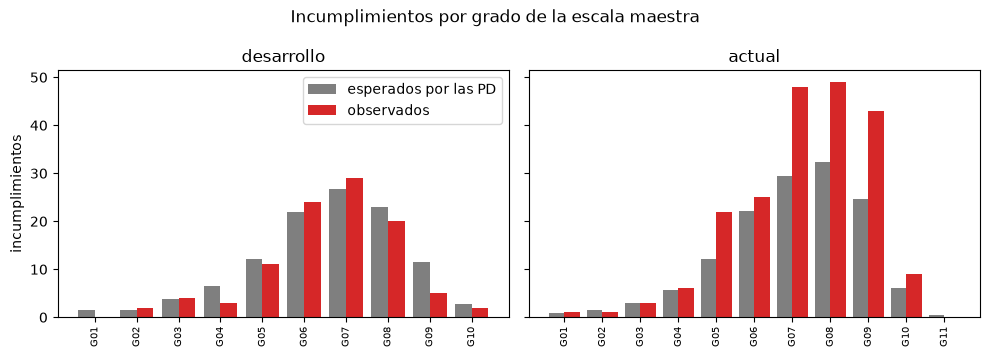

In [14]:
# Dibuja, por grado de la escala maestra, los incumplimientos esperados por las PD y los observados, en ambas muestras
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, (name, (pd_s, y_s)) in zip(axes, samples.items()):
    present = [g for g in grade_table(pd_s, y_s) if g["n"] > 0]
    positions = np.arange(len(present))
    expected = [g["pd"] * g["n"] for g in present]
    ax.bar(positions - 0.2, expected, width=0.4, label="esperados por las PD", color="tab:gray")
    ax.bar(positions + 0.2, [g["d"] for g in present], width=0.4, label="observados", color="tab:red")
    ax.set_xticks(positions)
    ax.set_xticklabels([g["grade"] for g in present], rotation=90, fontsize=7)
    ax.set_title(NAMES[name])
axes[0].set_ylabel("incumplimientos")
axes[0].legend()
fig.suptitle("Incumplimientos por grado de la escala maestra")
fig.tight_layout()
plt.show()

En cada grado, la barra gris es el número de incumplimientos que esperan las PD y la barra roja los incumplimientos observados. En la muestra de desarrollo, a la izquierda, las dos barras se acompañan a lo largo de los diez grados, con diferencias de unos pocos incumplimientos en uno u otro sentido. En la muestra actual, a la derecha, los incumplimientos observados superan a los esperados en los grados medios y altos: 48 contra unos 29 en G07, 49 contra 32 en G08 y 43 contra 25 en G09, con G05 también bien por encima. Ese es el patrón de un nivel demasiado bajo, y es la verdad con que se construyó la muestra. La figura no muestra que el exceso sea la misma proporción en todos los grados; las pruebas tratan los grados en conjunto.

### Paso 10: una batería no se detiene en el primer fallo

Un validador necesita el cuadro completo, así que una prueba que lanza una excepción se registra como un resultado en estado `error`, y las demás pruebas siguen corriendo. La celda siguiente toma tres tareas de la batería actual, reemplaza la del medio por una prueba de Jeffreys sobre una cartera de cero deudores, que debe fallar, y ejecuta la batería.

In [15]:
# Inserta una tarea que debe fallar (Jeffreys con cero deudores) y muestra que la batería la registra y termina
current_tasks = batteries["current"]
broken = [current_tasks[0], (cal.pd_jeffreys, dict(n=0, d=0, pd=0.05)), current_tasks[3]]
mixed = run_suite(broken, policy=policy, model_id="current", segment="portfolio")
states = [{"prueba": r.test_id, "estado": LIGHT[r.light.value]} for r in mixed.results]
print("peor semáforo:", LIGHT[mixed.worst().value])
print("conteos:", {LIGHT[key]: value for key, value in mixed.counts().items() if value})
pd.DataFrame(states)

peor semáforo: error
conteos: {'verde': 1, 'sin evaluar': 1, 'error': 1}


,prueba,estado
0,disc.auc,sin evaluar
1,pd.jeffreys,error
2,pd.binomial_vasicek,verde


La batería terminó las tres tareas: el AUC queda sin evaluar, la prueba de Jeffreys sobre cero deudores queda registrada en estado `error` y la binomial ajustada de Vasicek igual corrió y es verde. El peor semáforo es `error`, que es como una prueba que falla se anuncia en el resumen en vez de desaparecer de él. El motor guarda el texto de la excepción en las notas del resultado para que lo lea el validador. Lo que la batería no hace es inventar un valor para la prueba fallida; el vacío queda como vacío.

## Resultados

**Respuesta:** Sí. Con la política por defecto la batería deja en paz a la muestra de desarrollo calibrada, con seis resultados verdes y ninguno rojo, y encuentra la muestra actual: seis de sus nueve resultados son rojos, encabezados por el PSI con un valor p de 4,21e-10, mientras que el AUC de 0,779 no es menor que el AUC de desarrollo de 0,743 y la prueba de AUC frente al inicial sigue verde.

- **El contrato 1 rechazó exactamente lo que debía.** De las cinco filas escritas a mano rechazó la PD de 1,2, el desenlace `yes` y el identificador repetido, aceptó las otras dos y enumeró la columna extra como ignorada. Los dos archivos reales se aceptaron completos.
- **Las pruebas de nivel sostienen el hallazgo.** Las pruebas de Jeffreys, binomial, Hosmer-Lemeshow y Spiegelhalter son todas rojas con valores p bajo 1e-8, y el chi-cuadrado sobre grados es rojo en 2,65e-07. La figura por grado muestra la causa: desde G05, con G06 solo algo por encima, los incumplimientos observados superan lo que esperan las PD.
- **El ordenamiento está intacto.** Un modelo puede ordenar tan bien como en el desarrollo y estar mal dimensionado, y por eso una batería tiene pruebas de nivel además de pruebas de discriminación.
- **La binomial ajustada de Vasicek es verde.** Su valor p es 0,114: admitir una correlación de 0,04 absorbe el exceso, y aquí eso es un fallo. El precio de admitir correlación es la potencia.
- **El PSI es rojo aunque su valor, 0,0626, está dentro de la banda convencional de 0,10.** La referencia chi-cuadrado da un PSI crítico de 0,0169 al 5 %, y con 2.000 deudores por muestra detecta un desplazamiento que la regla empírica no ve.
- **Una prueba que falla no detiene la batería.** Se registra como `error` y las demás corren.

Lo que los semáforos no muestran: son la lectura de la política por defecto y no un veredicto de cumplimiento (notebook 03), y las muestras son sintéticas con verdad conocida, algo que las carteras reales nunca tienen.

## Resumen

- El contrato 1 convierte un CSV en registros aceptados e informa lo que rechazó, señaló o ignoró; nunca fuerza un valor.
- La escala maestra convierte las PD en doce grados, y la tabla de grados es la entrada de las pruebas por grado.
- `run_suite` ejecuta una lista de tareas `(función, argumentos)` bajo una política, registra una prueba que falla como resultado `error` y termina la batería.
- Las pruebas de nivel encuentran la muestra desplazada y dejan en paz a la calibrada; la prueba de ordenamiento no basta por sí sola; el PSI se lee frente a una referencia chi-cuadrado y no frente a una regla empírica.
- Cada prueba abierta tiene su propia distribución de referencia y sus grados de libertad, y el motor hace de los supuestos (`fitted`, `rho`) argumentos explícitos.

**Qué probar a continuación.** Pasa tu propia muestra puntuada por la puerta que el producto entrega para eso (`data-pipeline/validate.py`, véase `docs/guides/02_validate-your-own-model.md`) y compara su tabla con esta. Después lee `docs/guides/03_read-a-validation-report.md` y continúa con el tema 02, que construye los modelos que valida esta batería.

## Referencias

- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, secciones 2.5.3.1 y 2.5.4.1 y Anexo 1 (sección 3.1). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revised): la binomial, la binomial ajustada de Vasicek y el chi-cuadrado sobre grados. https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- Yurdakul, B. y Naranjo, J. (2020), Statistical properties of the population stability index, Journal of Risk Model Validation 14(4). https://doi.org/10.21314/JRMV.2020.227
- Hosmer, D. W. y Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- Spiegelhalter, D. J. (1986), Probabilistic prediction in patient management and clinical trials, Statistics in Medicine 5(5). https://doi.org/10.1002/sim.4780050506
- Este repositorio: `docs/guides/02_validate-your-own-model.md` y `docs/guides/03_read-a-validation-report.md`.